# Passo a passo · Regressão linear múltipla com scikit-learn
**Fundamentos de Machine Learning · Aula 2 · Prática guiada**

Neste notebook vamos percorrer **todas as fases** do treinamento de um modelo de regressão linear múltipla:

1. Carregar a base de um arquivo CSV com o pandas
2. Visualizar e entender a base
3. Separar as features (X) e o alvo (y)
4. Separar em treino e teste
5. Treinar o modelo (`fit`)
6. Interpretar os coeficientes
7. Fazer previsões (`predict`)
8. Visualizar o modelo otimizado em gráficos

Execute as células na ordem, lendo os comentários de cada etapa.

## A base de dados: *Advertising*

**Fonte:** James, Witten, Hastie e Tibshirani, *An Introduction to Statistical Learning*, cap. 2 (também disponível no Kaggle).

Cada linha representa um **mercado** (uma cidade ou região) onde o mesmo produto é vendido. São **200 mercados**. Para cada um, a base registra quanto foi investido em propaganda em cada mídia e quanto do produto foi vendido.

| Coluna | Tipo | O que representa | Unidade |
|---|---|---|---|
| *(sem nome)* | índice | Número da linha (1 a 200). Não é feature e é removida ao carregar | — |
| `TV` | feature | Orçamento de propaganda do produto em televisão naquele mercado | milhares de dólares |
| `Radio` | feature | Orçamento de propaganda do produto em rádio | milhares de dólares |
| `Newspaper` | feature | Orçamento de propaganda do produto em jornal | milhares de dólares |
| `Sales` | **alvo** | Vendas do produto naquele mercado | milhares de unidades |

**Exemplo de leitura:** a linha `230.1, 37.8, 69.2, 22.1` é um mercado em que se investiram US$ 230,1 mil em TV, US$ 37,8 mil em rádio e US$ 69,2 mil em jornal, e que vendeu 22,1 mil unidades.

**Contexto:** a empresa não controla as vendas diretamente, mas controla quanto investe em cada mídia. O objetivo do modelo é entender a relação entre esses orçamentos e as vendas, e descobrir qual canal traz mais retorno por dólar investido.

## Etapa 0 · Importar as bibliotecas

In [4]:
import numpy as np                                    # cálculos numéricos
import pandas as pd                                   # leitura e manipulação de tabelas
import matplotlib.pyplot as plt                       # gráficos

from sklearn.model_selection import train_test_split  # separação treino/teste
from sklearn.linear_model import LinearRegression     # o modelo de regressão linear

## Etapa 1 · Carregar o CSV com o pandas

`pd.read_csv` lê o arquivo e devolve um **DataFrame**, a tabela do pandas.

A versão do livro tem uma primeira coluna sem nome que é só o número da linha. Por isso removemos qualquer coluna `Unnamed`, o que funciona tanto para o arquivo do livro quanto para o do Kaggle.

In [5]:
CAMINHO = '../../data/advertising.csv'

df = pd.read_csv(CAMINHO)
df = df.drop(columns=[c for c in df.columns if c.startswith('Unnamed')])  # remove a coluna de índice, se existir

df.head()          # mostra as 5 primeiras linhas

,TV,Radio,Newspaper,Sales
0,230.1,37.8,69.2,22.1
1,44.5,39.3,45.1,10.4
2,17.2,45.9,69.3,12.0
3,151.5,41.3,58.5,16.5
4,180.8,10.8,58.4,17.9


## Etapa 2 · Visualizar a base

Antes de treinar qualquer modelo, sempre olhamos os dados. Queremos responder:
- Quantas linhas e colunas temos?
- Os tipos estão corretos (números são números)?
- Há valores ausentes?
- Qual a escala de cada variável?

In [6]:
print('Linhas e colunas:', df.shape)
print()
df.info()          # tipos de cada coluna e contagem de valores não nulos

Linhas e colunas: (200, 4)

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   TV         200 non-null    float64
 1   Radio      200 non-null    float64
 2   Newspaper  200 non-null    float64
 3   Sales      200 non-null    float64
dtypes: float64(4)
memory usage: 6.4 KB


In [7]:
df.isna().sum()    # quantidade de valores ausentes por coluna (esperamos zero)

TV           0
Radio        0
Newspaper    0
Sales        0
dtype: int64

In [8]:
df.describe().round(2)   # média, desvio, mínimo, quartis e máximo de cada coluna

,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,15.13
std,85.85,14.85,21.78,5.28
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,11.00
50%,149.75,22.90,25.75,16.00
75%,218.82,36.52,45.10,19.05
max,296.40,49.60,114.00,27.00


### Gráficos de dispersão: cada feature contra o alvo

Um gráfico por canal de propaganda. Observe em qual deles a relação com `Sales` parece mais forte (pontos mais alinhados) e em qual parece mais fraca.

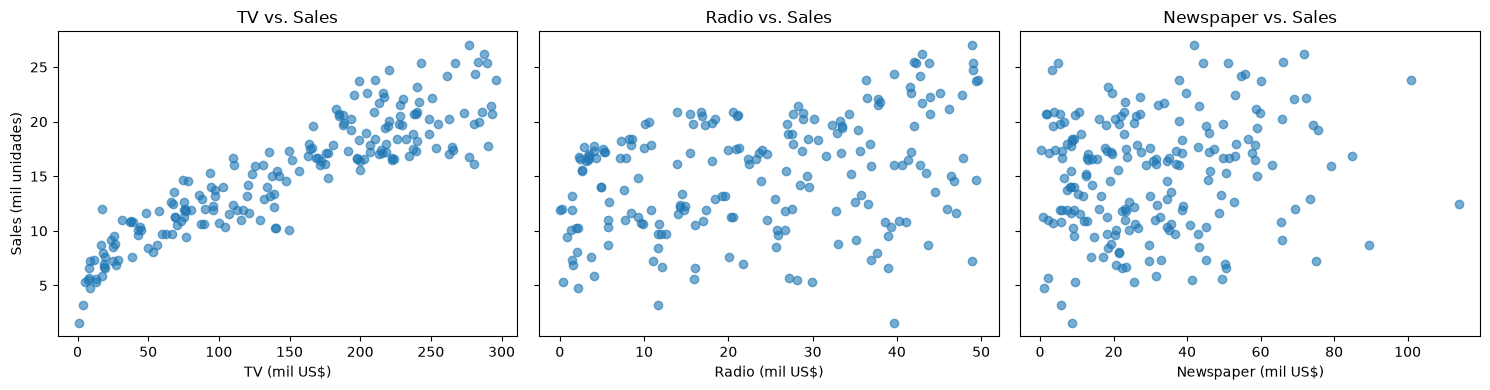

In [9]:
features = ['TV', 'Radio', 'Newspaper']

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, features):
    ax.scatter(df[col], df['Sales'], alpha=0.6)
    ax.set_xlabel(f'{col} (mil US$)')
    ax.set_title(f'{col} vs. Sales')
axes[0].set_ylabel('Sales (mil unidades)')
plt.tight_layout()
plt.show()

### Correlação entre as variáveis

A correlação vai de −1 a 1 e mede o quanto duas variáveis **andam juntas em linha reta**. Valores perto de 1 indicam que crescem juntas.

In [10]:
df.corr().round(2)

,TV,Radio,Newspaper,Sales
TV,1.00,0.05,0.06,0.90
Radio,0.05,1.00,0.35,0.35
Newspaper,0.06,0.35,1.00,0.16
Sales,0.90,0.35,0.16,1.00


**O que observar:** `TV` tem a relação mais forte com `Sales`, seguida por `Radio`. `Newspaper` tem relação fraca. Guarde isso: vamos conferir se os coeficientes do modelo contam a mesma história.

## Etapa 3 · Separar features (X) e alvo (y)

- **X** é a matriz de features. Deve ser **bidimensional** (um DataFrame), por isso os colchetes duplos.
- **y** é o vetor com o alvo.

In [11]:
X = df[['TV', 'Radio', 'Newspaper']]   # colchetes duplos -> DataFrame (2D)
y = df['Sales']                        # colchetes simples -> Series (1D)

print('X:', X.shape, '| y:', y.shape)

X: (200, 3) | y: (200,)


## Etapa 4 · Separar em treino e teste

O modelo aprende `a, b₁, b₂, b₃` usando **apenas o conjunto de treino**. O conjunto de teste fica guardado para depois: são mercados que o modelo **nunca viu**, e é neles que conferimos se as previsões continuam boas.

- `test_size=0.2`: 20% das linhas vão para o teste (40 mercados) e 80% para o treino (160).
- `random_state=42`: fixa o sorteio, para que todos na turma obtenham a mesma separação.

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

print('Treino:', X_train.shape, '| Teste:', X_test.shape)

Treino: (160, 3) | Teste: (40, 3)


## Etapa 5 · Treinar o modelo (`fit`)

O modelo é

$$\widehat{Sales} = a + b_1 \cdot TV + b_2 \cdot Radio + b_3 \cdot Newspaper$$

O método `fit` encontra os valores de `a` e `b` que **minimizam a soma dos erros quadráticos (SSE)** no treino. É o mesmo critério de mínimos quadrados da aula, agora com três features.

In [13]:
modelo = LinearRegression()      # 1. cria o modelo (ainda sem parâmetros aprendidos)
modelo.fit(X_train, y_train)     # 2. aprende a e b usando somente o treino

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](3,)","[0.05,0.1 ,0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](3,)","['TV','Radio','Newspaper']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,4.714
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,3
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(3)


## Etapa 6 · Ler os coeficientes

- `intercept_` é o **a**: as vendas previstas quando os três investimentos são zero.
- `coef_` traz os **b**, um por feature, **na mesma ordem das colunas de X**.

Interpretação de cada `b`: quantas mil unidades a mais esperamos vender para cada mil dólares a mais naquele canal, **mantendo os outros dois canais fixos**.

In [14]:
print(f'a (intercepto) = {modelo.intercept_:.4f}')

coeficientes = pd.DataFrame({'feature': X.columns, 'b': modelo.coef_})
coeficientes

a (intercepto) = 4.7141


,feature,b
0,TV,0.054509
1,Radio,0.100945
2,Newspaper,0.004337


**Para discutir:** compare os coeficientes com os gráficos de dispersão e a tabela de correlação. O coeficiente de `Newspaper` fica próximo de zero. Quando já sabemos quanto foi investido em TV e rádio, o jornal acrescenta pouca informação para prever as vendas.

## Etapa 7 · Fazer previsões (`predict`)

### 7.1 Previsões para mercados do conjunto de teste

In [15]:
y_pred = modelo.predict(X_test)          # previsão para os 40 mercados de teste

comparacao = X_test.copy()
comparacao['Sales_real'] = y_test
comparacao['Sales_previsto'] = y_pred.round(2)
comparacao['residuo'] = (comparacao['Sales_real'] - comparacao['Sales_previsto']).round(2)
comparacao.head(8)

,TV,Radio,Newspaper,Sales_real,Sales_previsto,residuo
95,163.3,31.6,52.9,16.9,17.03,-0.13
15,195.4,47.7,52.9,22.4,20.41,1.99
30,292.9,28.3,43.2,21.4,23.72,-2.32
158,11.7,36.9,45.2,7.3,9.27,-1.97
128,220.3,49.0,3.2,24.7,21.68,3.02
115,75.1,35.0,52.7,12.6,12.57,0.03
69,216.8,43.9,27.2,22.3,21.08,1.22
170,50.0,11.6,18.4,8.4,8.69,-0.29


### 7.2 Previsões para orçamentos novos

Simulamos três planos de mídia. As colunas devem ter **os mesmos nomes e a mesma ordem** usados no treino.

In [16]:
planos = pd.DataFrame({
    'TV':        [100,  50, 200],
    'Radio':     [ 20,  40,  10],
    'Newspaper': [ 30,  10,  50],
}, index=['Plano A', 'Plano B', 'Plano C'])

planos['Sales_previsto'] = modelo.predict(planos[['TV', 'Radio', 'Newspaper']]).round(2)
planos

,TV,Radio,Newspaper,Sales_previsto
Plano A,100,20,30,12.31
Plano B,50,40,10,11.52
Plano C,200,10,50,16.84


### 7.3 Conferindo a fórmula na mão

`predict` apenas aplica a equação ŷ = a + b₁·TV + b₂·Radio + b₃·Newspaper. Vamos refazer a conta do Plano A:

In [22]:
a = modelo.intercept_
b_tv, b_radio, b_news = modelo.coef_

manual = a + b_tv * 100 + b_radio * 20 + b_news * 30
print(f'Plano A pela fórmula: {manual:.2f}')
print(f'Plano A pelo predict: {planos.loc["Plano A", "Sales_previsto"]:.2f}')

Plano A pela fórmula: 12.31
Plano A pelo predict: 12.31


## Etapa 8 · Visualizar o modelo otimizado

Com três features, o modelo é um **hiperplano** em 4 dimensões, que não conseguimos desenhar diretamente. Usamos três visões complementares.

### 8.1 A reta otimizada de cada feature

Para cada canal, variamos só aquela feature e **fixamos as outras duas na média do treino**. O resultado é uma reta, a "fatia" do hiperplano naquela direção, e a inclinação dela é exatamente o `b` da feature.

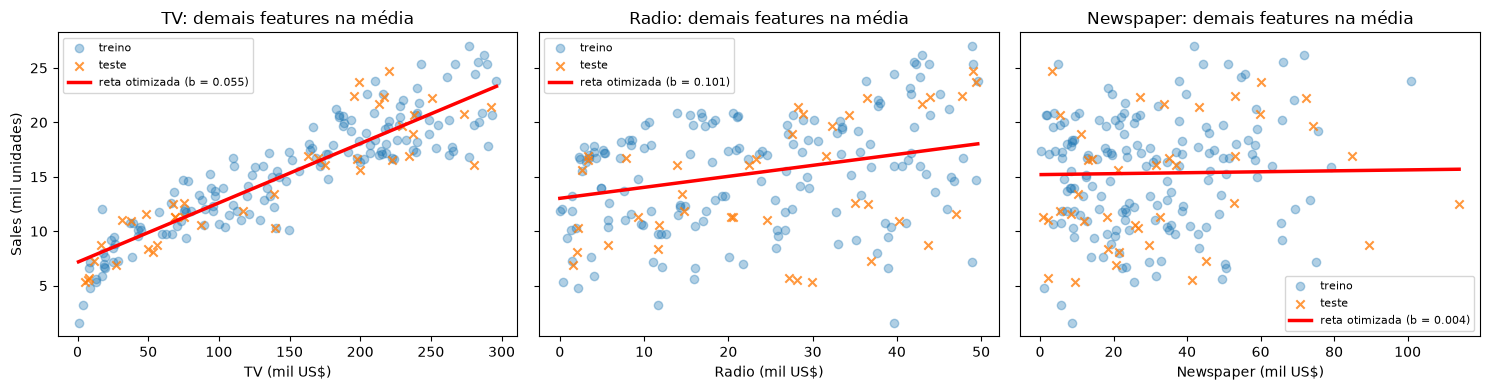

In [18]:
medias = X_train.mean()

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, col in zip(axes, features):
    # grade de valores só para a feature da vez; as outras ficam na média
    grade = pd.DataFrame([medias] * 100)
    grade[col] = np.linspace(X[col].min(), X[col].max(), 100)

    ax.scatter(X_train[col], y_train, alpha=0.35, label='treino')
    ax.scatter(X_test[col], y_test, alpha=0.8, marker='x', label='teste')
    ax.plot(grade[col], modelo.predict(grade), color='red', linewidth=2.5,
            label=f'reta otimizada (b = {modelo.coef_[features.index(col)]:.3f})')
    ax.set_xlabel(f'{col} (mil US$)')
    ax.set_title(f'{col}: demais features na média')
    ax.legend(fontsize=8)
axes[0].set_ylabel('Sales (mil unidades)')
plt.tight_layout()
plt.show()

Note que os pontos ficam espalhados em volta da reta, sobretudo em `Radio` e `Newspaper`. Isso é esperado: cada ponto tem os **seus próprios** valores das outras features, enquanto a reta fixa as outras na média.

### 8.2 O plano em 3D (TV e Radio)

`TV` e `Radio` são as features mais importantes. Fixando `Newspaper` na média, o modelo vira um **plano** que podemos desenhar em 3D. As linhas verticais são os resíduos dos mercados de teste.

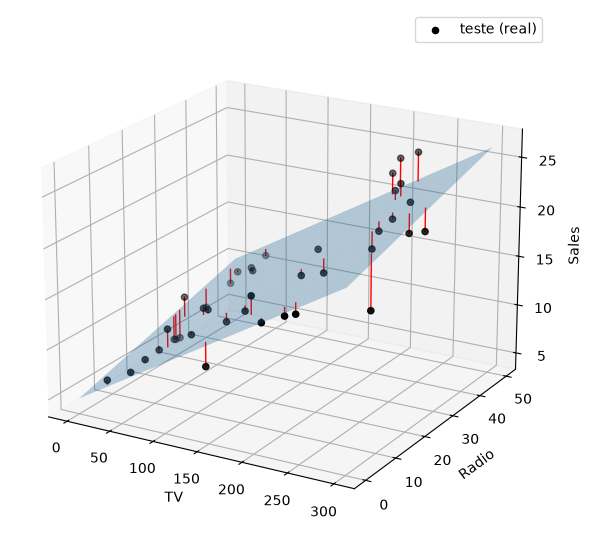

In [19]:
tv_g, radio_g = np.meshgrid(np.linspace(0, 300, 25), np.linspace(0, 50, 25))
grade3d = pd.DataFrame({'TV': tv_g.ravel(), 'Radio': radio_g.ravel(),
                        'Newspaper': medias['Newspaper']})
sales_g = modelo.predict(grade3d).reshape(tv_g.shape)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(projection='3d')
ax.plot_surface(tv_g, radio_g, sales_g, alpha=0.3, color='tab:blue')
ax.scatter(X_test['TV'], X_test['Radio'], y_test, color='black', s=20, label='teste (real)')

# resíduos: do ponto real até o plano
plano_teste = modelo.predict(X_test.assign(Newspaper=medias['Newspaper']))
for xt, rt, yr, yp in zip(X_test['TV'], X_test['Radio'], y_test, plano_teste):
    ax.plot([xt, xt], [rt, rt], [yr, yp], color='red', linewidth=1)

ax.set_xlabel('TV'); ax.set_ylabel('Radio'); ax.set_zlabel('Sales')
ax.view_init(elev=20, azim=-60)      # mude elev e azim para girar o gráfico
ax.legend()
plt.show()

### 8.3 Real vs. previsto no conjunto de teste

Este gráfico funciona com qualquer número de features. Cada ponto é um mercado de teste. Se o modelo fosse perfeito, todos os pontos cairiam sobre a diagonal tracejada (previsto = real). A distância vertical até a diagonal é o resíduo.

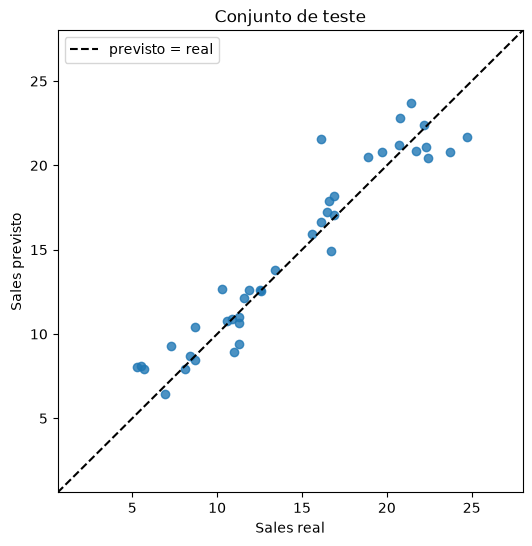

In [20]:
plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_pred, alpha=0.8)
limites = [y.min() - 1, y.max() + 1]
plt.plot(limites, limites, 'k--', label='previsto = real')
plt.xlim(limites); plt.ylim(limites)
plt.xlabel('Sales real'); plt.ylabel('Sales previsto')
plt.title('Conjunto de teste')
plt.legend()
plt.show()

### 8.4 Uma feature ou três?

Para ver o ganho da regressão múltipla, comparamos com um modelo que usa **só TV**. O critério é o SSE da aula, calculado nos mercados de **teste**.

In [21]:
def sse(real, previsto):
    return np.sum((real - previsto) ** 2)

modelo_tv = LinearRegression().fit(X_train[['TV']], y_train)

print(f"SSE no teste, só TV      : {sse(y_test, modelo_tv.predict(X_test[['TV']])):8.2f}")
print(f"SSE no teste, 3 features : {sse(y_test, y_pred):8.2f}")

SSE no teste, só TV      :   244.04
SSE no teste, 3 features :   116.31


## Resumo: a receita completa

```python
df = pd.read_csv('arquivo.csv')                         # 1. carregar
df.head(); df.info(); df.describe()                     # 2. visualizar
X, y = df[[...features...]], df['alvo']                 # 3. X (2D) e y (1D)
X_train, X_test, y_train, y_test = train_test_split(    # 4. treino e teste
    X, y, test_size=0.2, random_state=42)
modelo = LinearRegression().fit(X_train, y_train)       # 5. treinar
modelo.intercept_, modelo.coef_                         # 6. interpretar
modelo.predict(X_test)                                  # 7. prever
```

Na atividade, você vai aplicar esta mesma receita a outra base de dados.